In [7]:
import os

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import exposure, filters, img_as_ubyte, io, transform


/home/wiacker/dbAI/.venv/lib/python3.14/site-packages/skimage/_shared/utils.py:587: UserWarning: This might be a color image. The histogram will be computed on the flattened image. You can instead apply this function to each color channel, or set channel_axis.
  return func(*args, **kwargs)


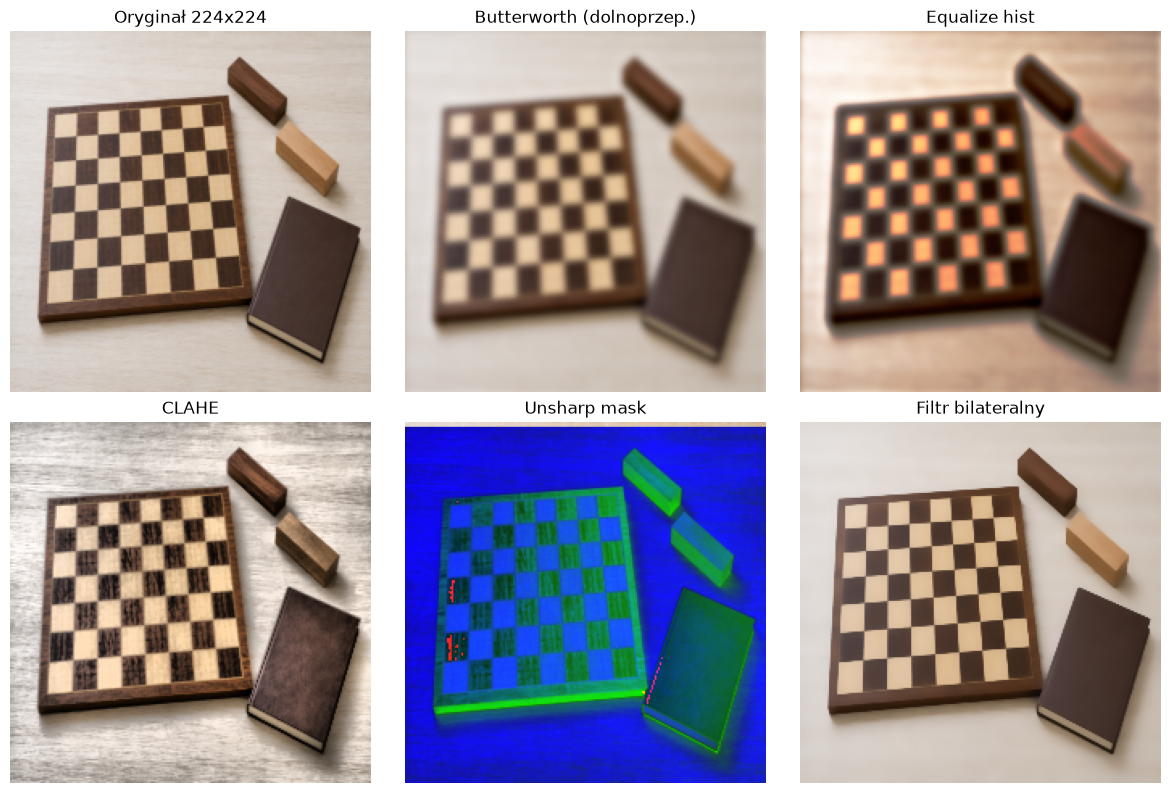

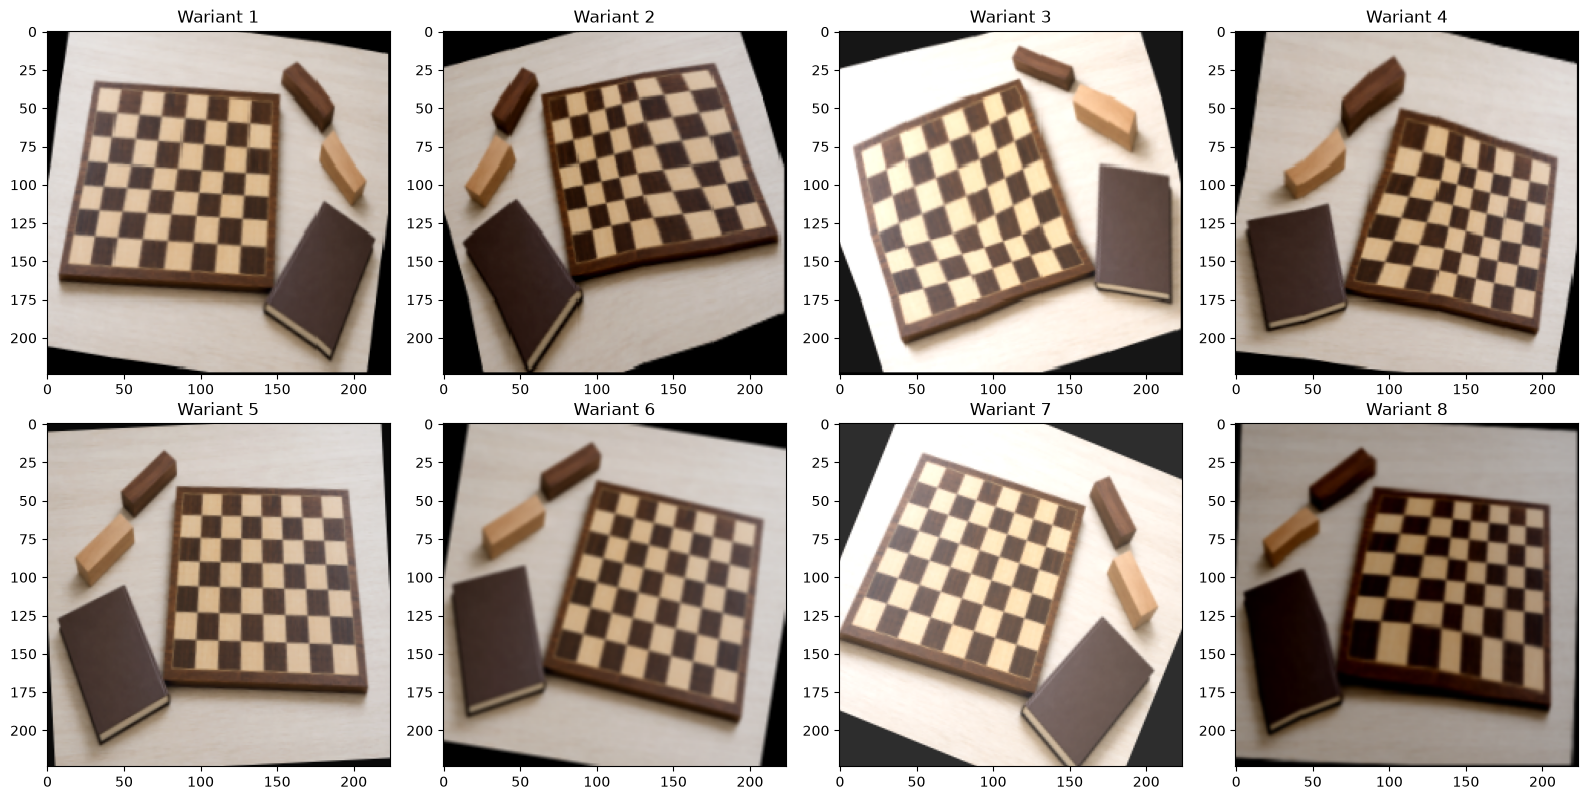

In [9]:
os.makedirs("output", exist_ok=True)

obraz = io.imread("obraz_naroza.jpg")
if obraz.ndim == 3 and obraz.shape[2] == 4:
    obraz = obraz[..., :3]

resized = transform.resize(obraz, (224, 224), anti_aliasing=True)  # float [0,1]
resized_u8 = img_as_ubyte(resized)

butter = np.clip(
    filters.butterworth(
        resized, cutoff_frequency_ratio=0.1, high_pass=False, channel_axis=-1
    ),
    0,
    1,
)
equalized = exposure.equalize_hist(butter)

clahe = exposure.equalize_adapthist(resized, clip_limit=0.03)
unsharp = np.clip(
    filters.unsharp_mask(resized, radius=2, amount=1.5, channel_axis=-1), 0, 1
)
bilateral = cv2.bilateralFilter(resized_u8, d=9, sigmaColor=75, sigmaSpace=75)

prep = [
    ("Oryginał 224x224", resized),
    ("Butterworth (dolnoprzep.)", butter),
    ("Equalize hist", equalized),
    ("CLAHE", clahe),
    ("Unsharp mask", unsharp),
    ("Filtr bilateralny", bilateral),
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (title, img) in zip(axes.ravel(), prep):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("output/preprocessing.png", dpi=150)
plt.show()

pipeline = A.Compose(
    [
        A.Resize(224, 224),
        A.HorizontalFlip(p=0.5),
        A.Rotate(limit=25, p=0.8),
        A.RandomBrightnessContrast(p=0.7),
        A.GridDistortion(p=0.5),
        A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    ]
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, ax in enumerate(axes.ravel(), start=1):
    wariant = pipeline(image=resized_u8)["image"]
    io.imsave(f"output/aug_{i}.png", wariant)
    ax.imshow(wariant)
    ax.set_title(f"Wariant {i}")
plt.tight_layout()
plt.savefig("output/augmentacje.png", dpi=150)
plt.show()